# Homework 6 · Stochastic birth–death process and the Gillespie algorithm

**Module 2 · stochastic** · *Hao-Tian Jin* · 2026-10-25

A single species $X$ is produced at a constant rate and degraded at a rate proportional to its own copy number. The notebook does three things:

1. writes the chemical master equation for the process and derives the dynamics of the mean from it;
2. derives the two sampling formulas used by the Gillespie algorithm;
3. implements the stochastic simulation algorithm (SSA) and tests the simulated trajectories against exact results.

Two exact results serve as benchmarks: the ensemble mean $\langle n(t)\rangle=\frac{\alpha}{\delta}(1-e^{-\delta t})$ for $n(0)=0$, and the Poisson stationary distribution with parameter $\alpha/\delta$.

# Part 1 · The birth–death process

## Reactions and propensities

The species $X$ undergoes two elementary reactions,

$$
\varnothing \xrightarrow{\ \alpha\ } X, \qquad X \xrightarrow{\ \delta\ } \varnothing,
$$

and the state is the integer copy number $n\ge 0$. Each reaction is described by a propensity $a_j(n)$, defined so that $a_j(n)\,\mathrm dt$ is the probability that reaction $j$ fires in the next infinitesimal interval $\mathrm dt$:

* **birth**, $a_1(n)=\alpha$: molecules are created at a constant rate independent of $n$ (zeroth order);
* **death**, $a_2(n)=\delta n$: each of the $n$ molecules decays independently at rate $\delta$, so the total decay rate is $n$ times the single-molecule rate (first order).

The state-change vectors are $\nu_1=+1$ and $\nu_2=-1$, and the total propensity is

$$
a_0(n)=a_1(n)+a_2(n)=\alpha+\delta n .
$$

## Chemical master equation

Let $P_n(t)=\mathbb P\{N(t)=n\}$. Probability flows into state $n$ from $n-1$ by a birth and from $n+1$ by a death, and leaves $n$ through either reaction:

$$
\frac{\mathrm dP_n}{\mathrm dt}
= \underbrace{\alpha P_{n-1}}_{\text{birth from } n-1}
- \underbrace{(\alpha+\delta n)P_n}_{\text{leaving } n}
+ \underbrace{\delta(n+1)P_{n+1}}_{\text{death from } n+1},
\qquad P_{-1}(t)\equiv 0 .
$$

## Mean dynamics

Let $A(t)=\sum_{n\ge 0} nP_n(t)=\langle N(t)\rangle$. Multiplying the master equation by $n$ and summing gives three terms, each evaluated with an index shift.

**1. Birth term.** Since $P_{-1}=0$, set $k=n-1$:

$$
\sum_{n\ge 0} n\,\alpha P_{n-1}
= \alpha\sum_{k\ge 0}(k+1)P_k
= \alpha\left(\sum_{k\ge 0}kP_k+\sum_{k\ge 0}P_k\right)
= \alpha(A+1),
$$

where $\sum_k P_k=1$ was used.

**2. Exit term.**

$$
-\sum_{n\ge 0} n(\alpha+\delta n)P_n
= -\alpha A-\delta\sum_{n\ge 0}n^2P_n .
$$

**3. Death term.** Set $k=n+1$:

$$
\sum_{n\ge 0} n\,\delta(n+1)P_{n+1}
= \delta\sum_{k\ge 1}(k-1)kP_k
= \delta\sum_{k\ge 0}(k^2-k)P_k
= \delta\sum_{n\ge 0}n^2P_n-\delta A .
$$

Adding the three contributions, the second-moment sums cancel exactly:

$$
\frac{\mathrm dA}{\mathrm dt}
= \alpha(A+1)-\alpha A-\delta\langle n^2\rangle+\delta\langle n^2\rangle-\delta A
= \alpha-\delta A .
$$

$$
\boxed{\ \frac{\mathrm dA}{\mathrm dt}=\alpha-\delta A\ }
$$

The cancellation is not an accident: all propensities are at most linear in $n$, so the equation for the first moment closes and involves no higher moments. With $A(0)=n_0$,

$$
A(t)=\frac{\alpha}{\delta}+\left(n_0-\frac{\alpha}{\delta}\right)e^{-\delta t}
\;\xrightarrow[\ n_0=0\ ]{}\;
\frac{\alpha}{\delta}\left(1-e^{-\delta t}\right).
$$

The stationary mean is $\alpha/\delta$ and the relaxation time is $1/\delta$.

## Stationary distribution

At stationarity the birth and death currents balance state by state (detailed balance for this birth–death chain):

$$
\alpha P_{n-1}=\delta nP_n
\quad\Longrightarrow\quad
P_n=\frac{(\alpha/\delta)^n}{n!}\,P_0 .
$$

Normalising gives $P_0=e^{-\alpha/\delta}$, hence

$$
P_n^\star=e^{-\lambda}\frac{\lambda^n}{n!},\qquad \lambda=\frac{\alpha}{\delta},
$$

a Poisson distribution. For a Poisson variable $\langle n\rangle=\mathrm{Var}(n)=\lambda$, so the Fano factor is $1$ and the relative standard deviation at stationarity is $1/\sqrt{\lambda}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})

# Part 2 · Where the Gillespie formulas come from

Each step of the SSA answers two questions: *when* does the next reaction occur, and *which* reaction is it. Both answers follow from the definition of the propensities alone.

## Waiting time: the exponential distribution

Fix the state $n$ and let $a_0=a_0(n)$ be the total propensity. As long as no reaction fires, the state does not change and the propensities stay constant. Divide $[t,t+\tau]$ into $m$ steps of length $\Delta t=\tau/m$. The probability of no reaction in one step is $1-a_0\Delta t+O(\Delta t^2)$, and the steps are independent, so

$$
S(\tau)=\mathbb P\{\text{no reaction in }[t,t+\tau]\}
=\lim_{m\to\infty}\left(1-\frac{a_0\tau}{m}\right)^{m}
=e^{-a_0\tau}.
$$

The same result follows from $S(\tau+\mathrm d\tau)=S(\tau)\,(1-a_0\,\mathrm d\tau)$, i.e. $\dot S=-a_0S$ with $S(0)=1$.

The waiting time $\tau^\ast$ to the next reaction therefore has

$$
F(\tau)=\mathbb P\{\tau^\ast\le\tau\}=1-e^{-a_0\tau},
\qquad
f(\tau)=a_0e^{-a_0\tau},
\qquad
\langle\tau^\ast\rangle=\frac{1}{a_0},
\quad
\mathrm{Var}(\tau^\ast)=\frac{1}{a_0^2}.
$$

**Sampling by inverse transform.** For $u\sim U(0,1)$ the CDF value $F(\tau^\ast)$ is also uniform. Setting $u=F(\tau)$ and solving for $\tau$,

$$
u=1-e^{-a_0\tau}
\;\Longrightarrow\;
\tau=-\frac{1}{a_0}\ln(1-u).
$$

Because $r_1=1-u$ is again uniform on $(0,1]$, this is exactly the update rule

$$
\boxed{\ \tau=\frac{1}{a_0}\ln\frac{1}{r_1}\ },\qquad r_1\sim U(0,1].
$$

The logarithm converts a uniform random number into an exponential waiting time; the factor $1/a_0$ sets its scale. A larger total propensity makes the system jump sooner.

## Which reaction: propensities act as probabilities

Suppose a reaction occurs at $t+\tau$. The joint probability that the next reaction is $\mu$ and that it occurs in $(\tau,\tau+\mathrm d\tau)$ is the density of waiting $\tau$, $a_0e^{-a_0\tau}$, times the conditional probability $a_\mu/a_0$:

$$
\mathbb P(\mu,\tau)=\frac{a_\mu}{a_0}\,a_0e^{-a_0\tau}\,\mathrm d\tau
= a_\mu e^{-a_0\tau}\,\mathrm d\tau .
$$

Marginalising over the waiting time,

$$
\mathbb P(\text{next reaction is }\mu)
=\int_0^\infty a_\mu e^{-a_0\tau}\,\mathrm d\tau
=\frac{a_\mu}{a_0}.
$$

The result does not depend on $\tau$: the waiting time and the identity of the reaction are independent, which is why two independent uniform numbers can be used.

**Sampling.** Place the propensities end to end on the interval $[0,a_0]$; reaction $\mu$ occupies a segment of length $a_\mu$. A point $r_2a_0$ with $r_2\sim U(0,1)$ falls in segment $\mu$ with probability $a_\mu/a_0$, so the reaction is the unique $\mu$ satisfying

$$
\sum_{j<\mu}a_j<r_2a_0\le\sum_{j\le\mu}a_j .
$$

For the two-reaction birth–death process this reduces to

$$
r_2a_0<a_1\ \Rightarrow\ \text{birth},
\qquad
r_2a_0\ge a_1\ \Rightarrow\ \text{death}.
$$

Since the waiting time uses only $a_0$ and the reaction choice uses only the ratios $a_\mu/a_0$, and both are recomputed after every event, the trajectories are exact samples of the master equation. No time step $\Delta t$ is involved.

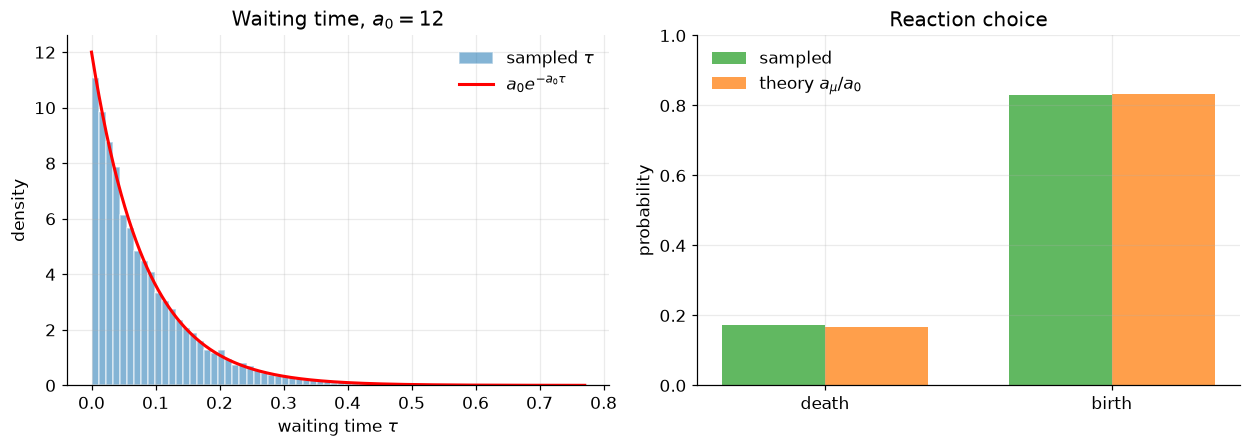

mean  tau : sampled 0.0837    theory 0.0833
std   tau : sampled 0.0827    theory 0.0833
P(birth)  : sampled 0.8288    theory 0.8333
P(death)  : sampled 0.1712    theory 0.1667


In [2]:
alpha, delta = 10.0, 0.1
n_state = 20
a_birth = alpha
a_death = delta * n_state
a0 = a_birth + a_death

n_draw = 20000
rng_check = np.random.default_rng(7)

r1 = 1.0 - rng_check.random(n_draw)          # uniform on (0, 1]
tau_samples = np.log(1.0 / r1) / a0          # inverse-transform sampling
r2 = rng_check.random(n_draw)
is_birth = r2 * a0 < a_birth                 # reaction selection

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

ax = axes[0]
ax.hist(tau_samples, bins=70, density=True, color="tab:blue", alpha=0.55,
        edgecolor="white", label=r"sampled $\tau$")
t_line = np.linspace(0.0, tau_samples.max(), 400)
ax.plot(t_line, a0 * np.exp(-a0 * t_line), "r-", lw=2,
        label=r"$a_0e^{-a_0\tau}$")
ax.set_xlabel(r"waiting time $\tau$")
ax.set_ylabel("density")
ax.set_title(rf"Waiting time, $a_0={a0:g}$")
ax.legend()

ax = axes[1]
sampled = [1.0 - is_birth.mean(), is_birth.mean()]
theory = [a_death / a0, a_birth / a0]
pos = np.arange(2)
ax.bar(pos - 0.18, sampled, width=0.36, color="tab:green", alpha=0.75,
       label="sampled")
ax.bar(pos + 0.18, theory, width=0.36, color="tab:orange", alpha=0.75,
       label=r"theory $a_\mu/a_0$")
ax.set_xticks(pos, ["death", "birth"])
ax.set_ylabel("probability")
ax.set_ylim(0, 1)
ax.set_title("Reaction choice")
ax.legend()

plt.tight_layout()
plt.show()

print(f"mean  tau : sampled {tau_samples.mean():.4f}    theory {1.0 / a0:.4f}")
print(f"std   tau : sampled {tau_samples.std():.4f}    theory {1.0 / a0:.4f}")
print(f"P(birth)  : sampled {is_birth.mean():.4f}    theory {a_birth / a0:.4f}")
print(f"P(death)  : sampled {(1.0 - is_birth).mean():.4f}    theory {a_death / a0:.4f}")

# Part 3 · Stochastic simulation of the birth–death process

The algorithm is the direct transcription of Part 2. At every step the propensities are evaluated at the current copy number, the waiting time is drawn from the exponential distribution with rate $a_0$, one reaction is chosen with probability $a_\mu/a_0$, and the state is updated by the corresponding state-change vector.

In [3]:
def gillespie_birth_death(alpha, delta, n0, t_max, seed=None):
    '''One exact SSA trajectory of the birth-death process.'''
    rng = np.random.default_rng(seed)
    t = 0.0
    n = n0
    times = [t]
    counts = [n]

    while t < t_max:
        a_birth = alpha
        a_death = delta * n
        a0 = a_birth + a_death
        if a0 <= 0:
            break

        r1 = 1.0 - rng.random()              # uniform on (0, 1]
        tau = np.log(1.0 / r1) / a0          # exponential waiting time

        r2 = rng.random()
        if r2 * a0 < a_birth:                # birth
            n += 1
        else:                                # death
            n -= 1

        t += tau
        times.append(t)
        counts.append(n)

    return np.array(times), np.array(counts)

## Simulation

The parameters follow the transcription/degradation example: production rate $\alpha=10$ per unit time and decay rate $\delta=0.1$ per molecule per unit time, so the stationary mean is $\lambda=\alpha/\delta=100$ and the relaxation time is $1/\delta=10$. Starting from an empty system ($n_0=0$) and running to $t=100$, the mean is within $0.005\%$ of its stationary value. $500$ independent trajectories are simulated.

In [4]:
alpha = 10.0
delta = 0.1
n0 = 0
t_max = 100.0
n_traj = 500

trajectories = [gillespie_birth_death(alpha, delta, n0, t_max, seed=2026 + i)
                for i in range(n_traj)]

n_events = sum(len(t) for t, _ in trajectories)
print(f"{n_traj} trajectories, {n_events:,} reaction events in total")

500 trajectories, 951,367 reaction events in total


## Ensemble mean versus the exact solution

To average the trajectories, the copy number is evaluated on a common time grid. Between two reaction events the state is constant, so the value on the grid is the value after the last event before that time (a forward step function, not a linear interpolation).

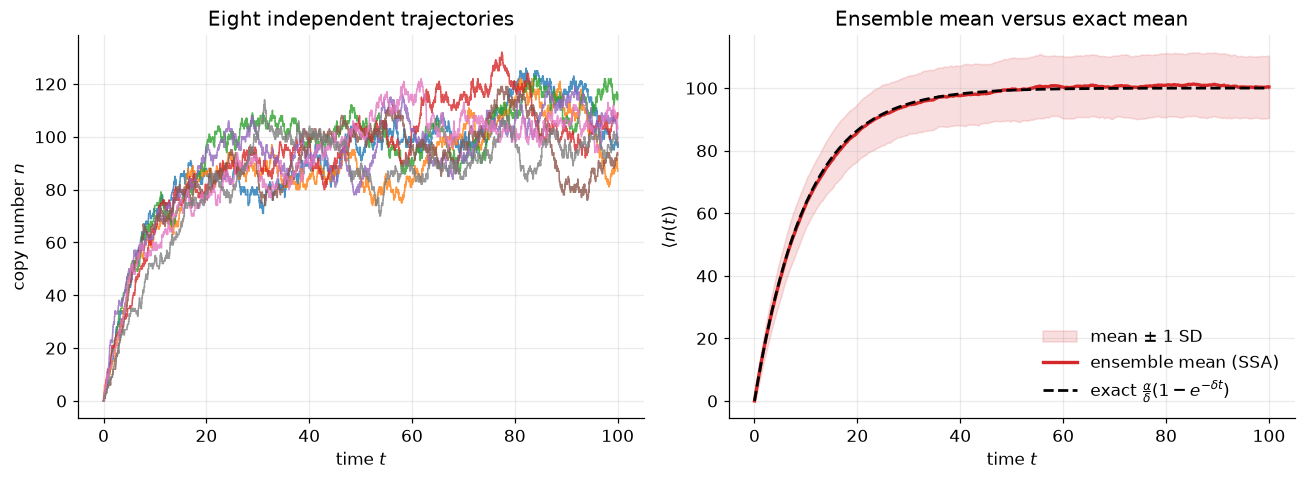

max |SSA mean - exact mean| = 1.292
mean copy number at t = 100: 100.362   exact 99.995


In [5]:
grid = np.linspace(0.0, t_max, 401)
counts_on_grid = np.array([
    n[np.searchsorted(t, grid, side="right") - 1] for t, n in trajectories
])
mean_n = counts_on_grid.mean(axis=0)
sd_n = counts_on_grid.std(axis=0, ddof=1)

A_exact = (alpha / delta) * (1.0 - np.exp(-delta * grid))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
for t, n in trajectories[:8]:
    ax.step(t, n, where="post", lw=1.0, alpha=0.8)
ax.set_xlabel(r"time $t$")
ax.set_ylabel(r"copy number $n$")
ax.set_title("Eight independent trajectories")

ax = axes[1]
ax.fill_between(grid, mean_n - sd_n, mean_n + sd_n, color="tab:red",
                alpha=0.15, label=r"mean $\pm$ 1 SD")
ax.plot(grid, mean_n, color="tab:red", lw=2.2, label="ensemble mean (SSA)")
ax.plot(grid, A_exact, "k--", lw=1.8,
        label=r"exact $\frac{\alpha}{\delta}(1-e^{-\delta t})$")
ax.set_xlabel(r"time $t$")
ax.set_ylabel(r"$\langle n(t)\rangle$")
ax.set_title("Ensemble mean versus exact mean")
ax.legend()

plt.tight_layout()
plt.show()

print(f"max |SSA mean - exact mean| = {np.max(np.abs(mean_n - A_exact)):.3f}")
print(f"mean copy number at t = {t_max:g}: {mean_n[-1]:.3f}   exact {A_exact[-1]:.3f}")

The ensemble mean of the simulations coincides with the solution of $\mathrm dA/\mathrm dt=\alpha-\delta A$ derived in Part 1, while every individual trajectory shows large fluctuations around it. These fluctuations are not simulation error: they are the variance that the deterministic ODE is blind to.

## Distribution at the final time

For $n_0=0$ the exact distribution is Poisson with mean $A(t)$. Two independent arguments give this. First, the stationary distribution is Poisson and $t=100=10/\delta$ is ten relaxation times, so the process has reached stationarity. Second, each molecule born at time $s$ survives to $t$ with probability $e^{-\delta(t-s)}$; thinning the Poisson birth process with this survival probability leaves a Poisson number of survivors with mean

$$
\int_0^t \alpha\,e^{-\delta(t-s)}\,\mathrm ds=\frac{\alpha}{\delta}\left(1-e^{-\delta t}\right)=A(t).
$$

The histogram of the $500$ final states is therefore compared with $\mathrm{Poisson}(A(t))$.

exact mean at t = 100 : 99.9955
empirical mean          : 100.3620
empirical variance      : 97.2254
Fano factor             : 0.9687   (exact 1)


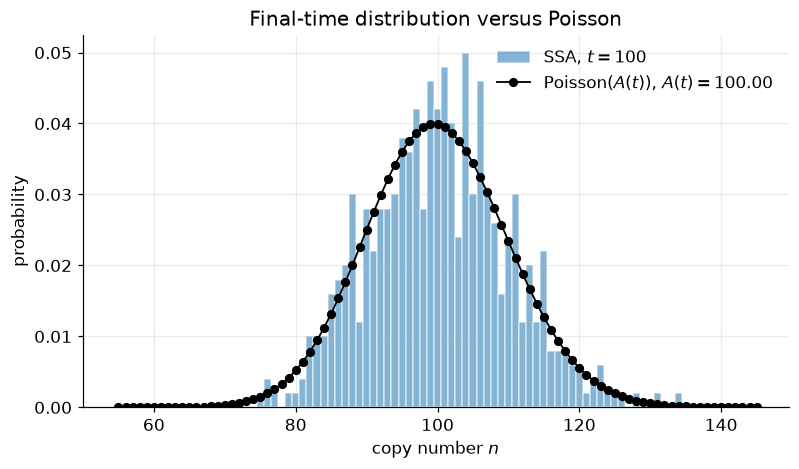

In [6]:
n_final = counts_on_grid[:, -1]
A_t = A_exact[-1]
emp_mean = n_final.mean()
emp_var = n_final.var(ddof=1)

print(f"exact mean at t = {t_max:g} : {A_t:.4f}")
print(f"empirical mean          : {emp_mean:.4f}")
print(f"empirical variance      : {emp_var:.4f}")
print(f"Fano factor             : {emp_var / emp_mean:.4f}   (exact 1)")

x = np.arange(55, 146)
fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.hist(n_final, bins=x - 0.5, density=True, color="tab:blue", alpha=0.55,
        edgecolor="white", label=r"SSA, $t=100$")
ax.plot(x, poisson.pmf(x, A_t), "ko-", ms=5, lw=1.2,
        label=rf"Poisson($A(t)$), $A(t)={A_t:.2f}$")
ax.set_xlabel(r"copy number $n$")
ax.set_ylabel("probability")
ax.set_title(r"Final-time distribution versus Poisson")
ax.legend()

plt.tight_layout()
plt.show()

# Discussion

* **The mean closes because the network is linear.** Both propensities, $\alpha$ and $\delta n$, are at most first order in $n$, so multiplying the master equation by $n$ and summing kills every second-moment term. The result, $\mathrm dA/\mathrm dt=\alpha-\delta A$, is identical to the mass-action ODE, and the simulated ensemble mean follows it to within a fraction of a molecule.
* **Both Gillespie formulas have a single origin.** The waiting time is exponential because the probability of no reaction decays multiplicatively, $S(\tau+\mathrm d\tau)=S(\tau)(1-a_0\mathrm d\tau)$, and the reaction probabilities are $a_\mu/a_0$ because the joint density $a_\mu e^{-a_0\tau}$ factorises. The two uniform random numbers therefore sample the exact waiting time and the exact reaction identity.
* **Exactness.** The SSA makes no time discretisation: it jumps from event to event, so the generated trajectories are statistically exact solutions of the master equation. Its only cost is that each trajectory must be simulated event by event.
* **The ODE captures only the mean.** The stationary copy number is Poisson with Fano factor $1$, so the absolute fluctuation at stationarity is $\sqrt{\lambda}=\sqrt{\alpha/\delta}$. With $\lambda=100$ this is about $10\%$; for a species with $\lambda=4$ it would be $50\%$, and the deterministic description would be qualitatively misleading.
* **What the simulation adds.** The ODE predicts $\langle n(t)\rangle$; the SSA also predicts the spread, the shape of the distribution and the probability of rare states (for example $n=0$ or $n$ far above $\alpha/\delta$), which is what matters for cell-to-cell variability and for switching behaviour at low copy numbers.

# Why the SSA is equivalent to the master equation

Parts 2 and 3 used the Gillespie formulas and verified their output. The remaining question is why the algorithm reproduces the master equation exactly, rather than approximately. The answer is a short calculation: the sampling rules of Part 2 give the transition rates that define the master equation, and the master equation is the forward equation of the resulting Markov chain.

**From the SSA to the master equation.** Fix the state $n$ and an infinitesimal interval $\mathrm dt$. The survival function of Part 2 gives

$$
\mathbb P\{\text{no reaction in }\mathrm dt\}=e^{-a_0(n)\,\mathrm dt}=1-a_0(n)\,\mathrm dt+O(\mathrm dt^2),
$$

and, since the waiting time and the reaction identity are independent,

$$
\mathbb P\{\text{reaction }\mu\text{ in }\mathrm dt\}
=\big(a_0(n)\,\mathrm dt+O(\mathrm dt^2)\big)\frac{a_\mu(n)}{a_0(n)}
=a_\mu(n)\,\mathrm dt+O(\mathrm dt^2).
$$

The factor $a_0$ cancels: the choice probability $a_\mu/a_0$ is precisely what converts the total rate $a_0$ into the individual rate $a_\mu$. Conditioning on the state at time $t$ and summing over the ways of reaching $n$,

$$
P_n(t+\mathrm dt)
=P_n(t)\big[1-a_0(n)\,\mathrm dt\big]
+\alpha P_{n-1}(t)\,\mathrm dt
+\delta(n+1)P_{n+1}(t)\,\mathrm dt
+O(\mathrm dt^2).
$$

Subtracting $P_n(t)$, dividing by $\mathrm dt$ and letting $\mathrm dt\to0$ gives exactly the master equation of Part 1. The $\mathrm dt$ here is only the bookkeeping variable of the derivative; the algorithm itself never chooses it.

**From the master equation to the SSA.** Define the generator acting on functions $f$ of the copy number,

$$
(\mathcal Lf)(n)=\alpha\big[f(n+1)-f(n)\big]+\delta n\big[f(n-1)-f(n)\big].
$$

For a single SSA step,

$$
\mathbb E\big[f(N(t+\mathrm dt))-f(N(t))\,\big|\,N(t)=n\big]
=(\mathcal Lf)(n)\,\mathrm dt+O(\mathrm dt^2),
$$

because with probability $1-a_0(n)\,\mathrm dt$ the state does not change, and with probability $a_\mu(n)\,\mathrm dt$ it changes by the $\mu$-th state-change vector. Hence

$$
\frac{\mathrm d}{\mathrm dt}\mathbb E\big[f(N(t))\big]=\mathbb E\big[(\mathcal Lf)(N(t))\big].
$$

Taking $f=\mathbf 1_n$ turns this into the master equation,

$$
(\mathcal L^\ast P)_n=\alpha P_{n-1}-(\alpha+\delta n)P_n+\delta(n+1)P_{n+1}.
$$

The generator determines the law of a continuous-time Markov chain uniquely (the forward equation has a unique solution for a given initial distribution), so an SSA trajectory is a realisation of the unique solution of the master equation, for every initial condition.

**What this does and does not say.** The equality is distributional: one trajectory is random, while the ensemble reproduces $P_n(t)$. It also explains the numerical results of Part 3: the ensemble mean follows $\mathrm dA/\mathrm dt=\alpha-\delta A$, and at stationarity the histogram is Poisson with Fano factor $1$. Exactness does not rely on the propensities being linear. The derivation uses only the rates $a_\mu(n)$, so the same argument holds for nonlinear reaction networks, where the master equation usually has no closed-form solution. A scheme that advances time in fixed steps and applies reaction probabilities $a_\mu(n)\Delta t$ is instead correct only to first order in $\Delta t$; the SSA samples the $\Delta t\to 0$ limit directly, and its remaining error is purely the Monte Carlo error of a finite ensemble.
